# Demand

In [1]:
import pandas as pd

df_demand = pd.read_csv('demand_cleaned.csv')

df_demand

,order_id,order_date,required_date,shipped_date,store_id,store_name,product_id,product_name,brand_id,brand_name,category_id,category_name,model_year,quantity,price
0,1,2016-01-01,2016-01-03,2016-01-03,1,Santa Cruz Bikes,20,Electra Townie Original 7D EQ - Women's - 2016,1,Electra,3,Cruisers Bicycles,2016,1,599.99
1,1,2016-01-01,2016-01-03,2016-01-03,1,Santa Cruz Bikes,8,Trek Remedy 29 Carbon Frameset - 2016,9,Trek,6,Mountain Bikes,2016,2,1799.99
2,1,2016-01-01,2016-01-03,2016-01-03,1,Santa Cruz Bikes,10,Surly Straggler - 2016,8,Surly,4,Cyclocross Bicycles,2016,2,1549.00
3,1,2016-01-01,2016-01-03,2016-01-03,1,Santa Cruz Bikes,16,Electra Townie Original 7D EQ - 2016,1,Electra,3,Cruisers Bicycles,2016,2,599.99
4,1,2016-01-01,2016-01-03,2016-01-03,1,Santa Cruz Bikes,4,Trek Fuel EX 8 29 - 2016,9,Trek,6,Mountain Bikes,2016,1,2899.99
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4717,1614,2018-11-28,2018-11-28,NaN,3,Rowlett Bikes,159,Trek Emonda ALR 6 - 2018,9,Trek,7,Road Bikes,2018,2,2299.99
4718,1614,2018-11-28,2018-11-28,NaN,3,Rowlett Bikes,213,Electra Cruiser 1 - 2016/2017/2018,1,Electra,3,Cruisers Bicycles,2018,2,269.99
4719,1615,2018-12-28,2018-12-28,NaN,3,Rowlett Bikes,197,Trek Verve+ Lowstep - 2018,9,Trek,5,Electric Bikes,2018,2,2299.99
4720,1615,2018-12-28,2018-12-28,NaN,3,Rowlett Bikes,214,Electra Tiger Shark 3i - 2018,1,Electra,3,Cruisers Bicycles,2018,1,899.99


Transforming dates into the correct format

In [2]:
df_demand['order_date'] = pd.to_datetime(df_demand['order_date'])
df_demand['required_date'] = pd.to_datetime(df_demand['required_date'])
df_demand['shipped_date'] = pd.to_datetime(df_demand['shipped_date'])

In [3]:
df_demand['order_to_required_days'] = (df_demand['required_date'] - df_demand['order_date']).dt.days
df_demand['order_to_ship_days'] = (df_demand['shipped_date'] - df_demand['order_date']).dt.days
df_demand['shipped_vs_required_days'] = (df_demand['shipped_date'] - df_demand['required_date']).dt.days

Categorizing orders status

In [4]:
import numpy as np

conditions = [df_demand['shipped_date'].isnull(), df_demand['shipped_vs_required_days']>= 0, df_demand['shipped_vs_required_days'] < 0, ]

choices = ['Pending', 'OnTime', 'Late']

df_demand['delivery_status'] = np.select(conditions, choices, default='Unknown')


Statistics

In [5]:
df_demand.describe()

,order_id,order_date,required_date,shipped_date,store_id,product_id,brand_id,category_id,model_year,quantity,price,order_to_required_days,order_to_ship_days,shipped_vs_required_days
count,4722.000000,4722,4722,4214,4722.000000,4722.000000,4722.000000,4722.000000,4722.000000,4722.000000,4722.000000,4722.000000,4214.000000,4214.000000
mean,821.265354,2017-04-04 22:18:26.988564,2017-04-06 16:56:25.006353,2017-03-01 00:03:04.527764,1.897289,59.366158,4.939221,3.767471,2016.630877,1.498941,1212.707872,1.776366,1.979829,-0.010679
min,1.000000,2016-01-01 00:00:00,2016-01-03 00:00:00,2016-01-03 00:00:00,1.000000,2.000000,1.000000,1.000000,2016.000000,1.000000,89.990000,0.000000,1.000000,-2.000000
25%,423.250000,2016-09-06 12:00:00,2016-09-09 06:00:00,2016-08-23 00:00:00,2.000000,14.000000,1.000000,2.000000,2016.000000,1.000000,429.000000,1.000000,1.000000,-1.000000
50%,828.500000,2017-04-09 00:00:00,2017-04-10 00:00:00,2017-03-10 00:00:00,2.000000,28.000000,5.000000,3.000000,2017.000000,1.000000,599.990000,2.000000,2.000000,0.000000
75%,1226.000000,2017-11-04 00:00:00,2017-11-06 00:00:00,2017-09-14 18:00:00,2.000000,84.000000,9.000000,6.000000,2017.000000,2.000000,1549.000000,3.000000,3.000000,1.000000
max,1615.000000,2018-12-28 00:00:00,2018-12-28 00:00:00,2018-04-02 00:00:00,3.000000,315.000000,9.000000,7.000000,2018.000000,2.000000,11999.990000,3.000000,3.000000,2.000000
std,465.152168,NaN,NaN,NaN,0.559372,67.312708,3.487915,1.985901,0.692138,0.500052,1352.798257,0.995206,0.809873,1.136591


In [6]:
columns_dates = ['order_to_required_days','order_to_ship_days','shipped_vs_required_days',]
df_demand[columns_dates].describe()

,order_to_required_days,order_to_ship_days,shipped_vs_required_days
count,4722.000000,4214.000000,4214.000000
mean,1.776366,1.979829,-0.010679
std,0.995206,0.809873,1.136591
min,0.000000,1.000000,-2.000000
25%,1.000000,1.000000,-1.000000
50%,2.000000,2.000000,0.000000
75%,3.000000,3.000000,1.000000
max,3.000000,3.000000,2.000000


In [7]:
df_demand['delivery_status'].value_counts()

delivery_status
OnTime     2780
Late       1434
Pending     508
Name: count, dtype: int64

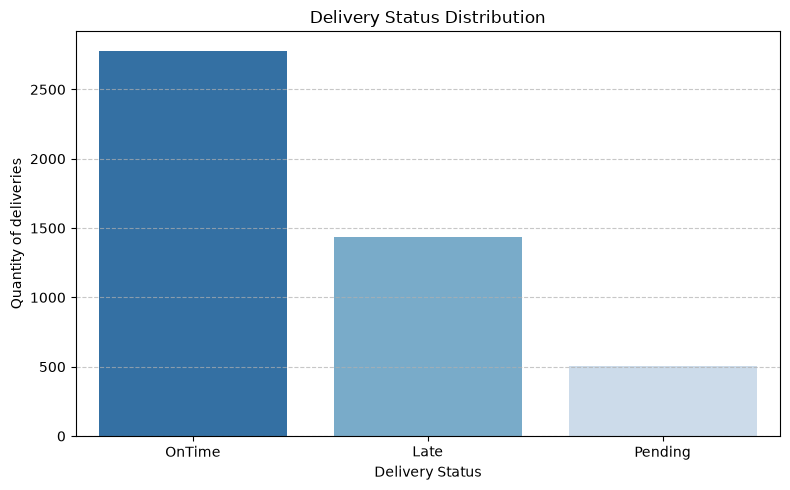

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

status_counts = df_demand['delivery_status'].value_counts()

plt.figure(figsize=(8, 5))
ax = sns.barplot(
    x=status_counts.index,
    y=status_counts.values,
    hue=status_counts.index,
    palette='Blues_r',
    legend=False,
)
plt.title('Delivery Status Distribution')
plt.xlabel('Delivery Status')
plt.ylabel('Quantity of deliveries')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

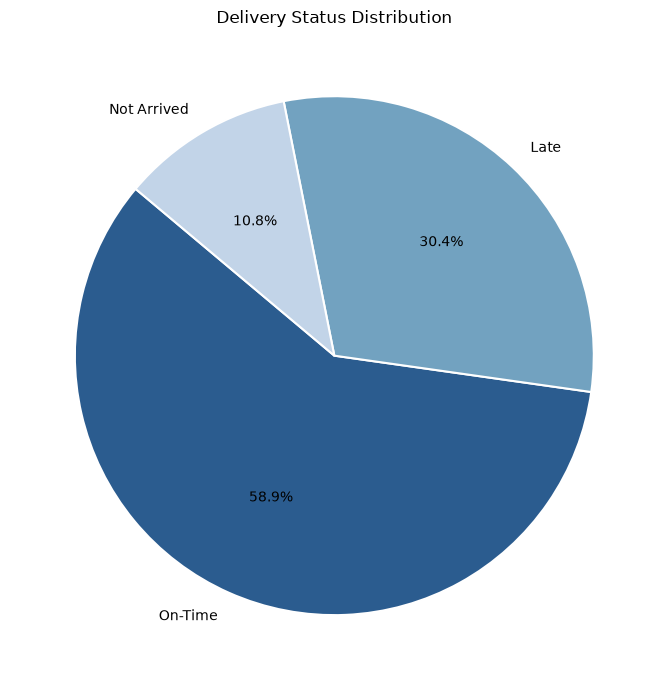

In [9]:
labels = ['On-Time', 'Late', 'Not Arrived']
sizes = [2780, 1434, 508]  
colors = ['#2b5c8f', '#72a2c0', '#c2d4e8']

plt.figure(figsize=(7, 7))
plt.pie(
    sizes,
    labels=labels,
    autopct='%1.1f%%',
    startangle=140,
    colors=colors,
    wedgeprops={'edgecolor': 'white', 'linewidth': 1.5},
)

plt.title('Delivery Status Distribution')
plt.tight_layout()
plt.show()

         store_name  quantity
0     Baldwin Bikes      4779
2  Santa Cruz Bikes      1516
1     Rowlett Bikes       783


C:\Users\pablo\AppData\Local\Temp\ipykernel_16464\820130031.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


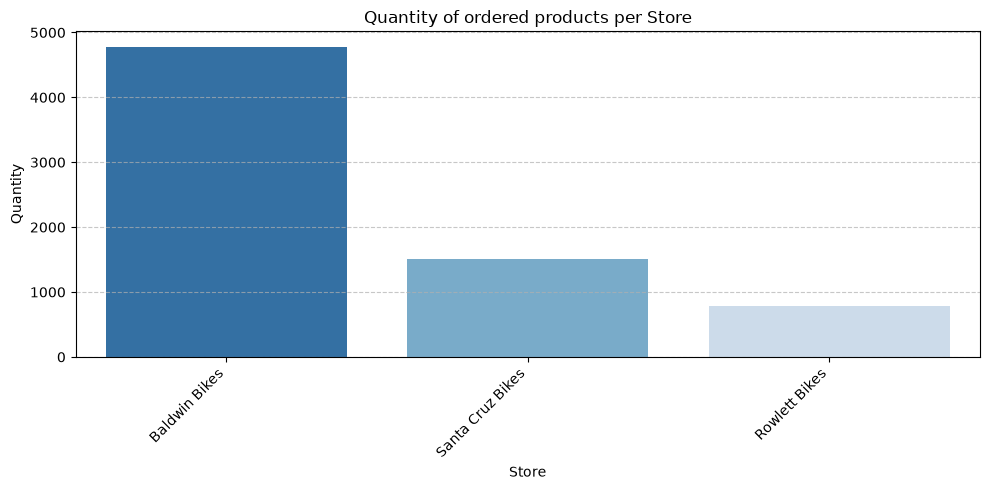

In [10]:
df_store_qty = df_demand.groupby('store_name')['quantity'].sum().reset_index()

df_store_qty = df_store_qty.sort_values(by='quantity', ascending=False)

print(df_store_qty)

plt.figure(figsize=(10, 5))
sns.barplot(
    data=df_store_qty, 
    x='store_name', 
    y='quantity', 
    palette='Blues_r'
)
plt.title('Quantity of ordered products per Store')
plt.xlabel('Store')
plt.ylabel('Quantity')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

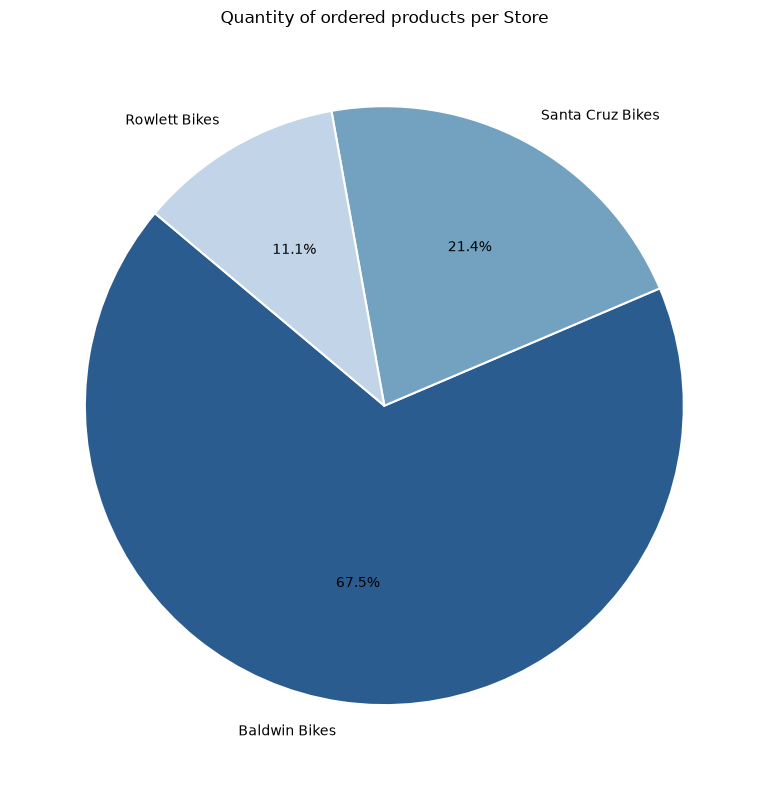

In [11]:
df_store_qty = df_demand.groupby('store_name')['quantity'].sum().reset_index()
df_store_qty = df_store_qty.sort_values(by='quantity', ascending=False)

plt.figure(figsize=(8, 8))
plt.pie(
    df_store_qty['quantity'],
    labels=df_store_qty['store_name'],
    autopct='%1.1f%%',
    startangle=140,
    colors=['#2b5c8f', '#72a2c0', '#c2d4e8'],
    wedgeprops={'edgecolor': 'white', 'linewidth': 1.5}
)

plt.title('Quantity of ordered products per Store')
plt.tight_layout()
plt.show()

In [12]:
df_demand['order_year'] = df_demand['order_date'].dt.year

df_grouped = (
    df_demand.groupby(['order_year', 'product_name'], )['quantity']
    .sum()
    .reset_index()
)

idx_max = df_grouped.groupby('order_year')['quantity'].idxmax()
top_products_per_year = df_grouped.loc[idx_max]

top_products_per_year

,order_year,product_name,quantity
0,2016,Electra Cruiser 1 (24-Inch) - 2016,237
41,2017,Electra Townie Original 7D EQ - 2016,75
196,2018,Electra Townie Original 21D EQ - 2017/2018,16


In [13]:
quantity_per_year = (
    df_demand.groupby('order_year')['quantity'].sum().reset_index()
)
quantity_per_year.columns = ['order_year', 'total_quantity']

quantity_per_year

,order_year,total_quantity
0,2016,2663
1,2017,3099
2,2018,1316


In [14]:
df_demand['order_date'] = pd.to_datetime(df_demand['order_date'])
df_demand['order_year'] = df_demand['order_date'].dt.year

df_grouped = (
    df_demand.groupby(['order_year', 'product_name'])['quantity']
    .sum()
    .reset_index()
)

top_3_products_per_year = (
    df_grouped.sort_values(['order_year', 'quantity'], ascending=[True, False])
    .groupby('order_year')
    .head(3)
)

top_3_products_per_year

,order_year,product_name,quantity
0,2016,Electra Cruiser 1 (24-Inch) - 2016,237
4,2016,Electra Townie Original 21D - 2016,217
6,2016,Electra Townie Original 7D EQ - 2016,213
41,2017,Electra Townie Original 7D EQ - 2016,75
29,2017,"Electra Girl's Hawaii 1 16 - 2017""""",68
64,2017,Sun Bicycles Cruz 3 - 2017,62
196,2018,Electra Townie Original 21D EQ - 2017/2018,16
194,2018,Electra Townie Original 21D - 2016,15
179,2018,Electra Townie Balloon 3i EQ Ladies' - 2018,14


In [15]:
df_brand_year = (
    df_demand.groupby(['order_year', 'brand_name'])['quantity']
    .sum()
    .reset_index()
)

idx_max = df_brand_year.groupby('order_year')['quantity'].idxmax()
top_brand_per_year = df_brand_year.loc[idx_max]

top_brand_per_year

,order_year,brand_name,quantity
0,2016,Electra,1296
13,2017,Trek,871
22,2018,Trek,532


In [16]:
df_demand['order_date'] = pd.to_datetime(df_demand['order_date'])

df_demand['order_year'] = df_demand['order_date'].dt.year
df_demand['order_month'] = df_demand['order_date'].dt.month

monthly_quantities = pd.pivot_table(
    df_demand,
    values='quantity',
    index='order_month',
    columns='order_year',
    aggfunc='sum',
    fill_value=0
)

monthly_quantities.index = [
    'Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun', 
    'Jul', 'Ago', 'Sep', 'Oct', 'Nov', 'Dic'
]

monthly_quantities

order_year,2016,2017,2018
Ene,221,229,241
Feb,223,263,160
Mar,213,296,290
Abr,176,248,580
May,224,241,0
Jun,199,296,1
Jul,211,249,11
Ago,251,287,9
Sep,281,237,4
Oct,254,296,8


In [17]:
import pandas as pd

df_demand['order_date'] = pd.to_datetime(df_demand['order_date'])
df_filtered = df_demand[df_demand['order_date'].dt.year.isin([2016, 2017])].copy()

df_filtered['order_year'] = df_filtered['order_date'].dt.year
df_filtered['order_month'] = df_filtered['order_date'].dt.month

monthly_quantities = pd.pivot_table(
    df_filtered,
    values='quantity',
    index='order_month',
    columns='order_year',
    aggfunc='sum',
    fill_value=0
)

monthly_percentage = (monthly_quantities / monthly_quantities.sum()) * 100

months_en = [
    'Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 
    'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'
]
monthly_quantities.index = months_en
monthly_percentage.index = months_en

display(monthly_quantities)

display(monthly_percentage.round(2))

order_year,2016,2017
Jan,221,229
Feb,223,263
Mar,213,296
Apr,176,248
May,224,241
Jun,199,296
Jul,211,249
Aug,251,287
Sep,281,237
Oct,254,296


order_year,2016,2017
Jan,8.30,7.39
Feb,8.37,8.49
Mar,8.00,9.55
Apr,6.61,8.00
May,8.41,7.78
Jun,7.47,9.55
Jul,7.92,8.03
Aug,9.43,9.26
Sep,10.55,7.65
Oct,9.54,9.55


In [18]:
df_demand['order_date'] = pd.to_datetime(df_demand['order_date'])
df_filtered = df_demand[df_demand['order_date'].dt.year.isin([2016, 2017])].copy()

df_filtered['order_year'] = df_filtered['order_date'].dt.year
df_filtered['order_month'] = df_filtered['order_date'].dt.month

monthly_table = pd.pivot_table(
    df_filtered,
    values='quantity',
    index='order_month',
    columns='order_year',
    aggfunc='sum',
    fill_value=0
)

monthly_table.index = [
    'Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 
    'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'
]

total_combined = monthly_table.sum().sum()
monthly_table['Total_Relative_%'] = ((monthly_table[2016] + monthly_table[2017]) / total_combined) * 100

annual_totals = monthly_table.sum(numeric_only=True)
annual_totals.name = 'Total Year'
monthly_table = pd.concat([monthly_table, pd.DataFrame(annual_totals).T])

monthly_table.round(2)

order_year,2016,2017,Total_Relative_%
Jan,221.0,229.0,7.81
Feb,223.0,263.0,8.43
Mar,213.0,296.0,8.83
Apr,176.0,248.0,7.36
May,224.0,241.0,8.07
Jun,199.0,296.0,8.59
Jul,211.0,249.0,7.98
Aug,251.0,287.0,9.34
Sep,281.0,237.0,8.99
Oct,254.0,296.0,9.55


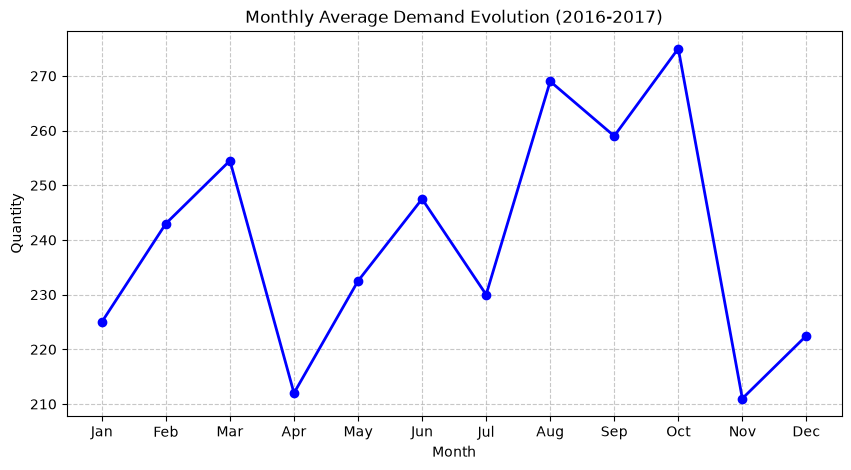

In [30]:
months_df = monthly_table.drop('Total Year', errors='ignore')

media_mensual = (months_df[2016] + months_df[2017]) / 2

plt.figure(figsize=(10, 5))
plt.plot(media_mensual.index, media_mensual.values, marker='o', linestyle='-', color='b', linewidth=2)

plt.title('Monthly Average Demand Evolution (2016-2017)')
plt.xlabel('Month')
plt.ylabel('Quantity')
plt.grid(True, linestyle='--', alpha=0.7)

plt.show()

In [20]:
monthly_demand = (
    df_demand.groupby(['order_year', 'order_month'])['quantity']
    .sum()
    .reset_index()
)

monthly_demand

,order_year,order_month,quantity
0,2016,1,221
1,2016,2,223
2,2016,3,213
3,2016,4,176
4,2016,5,224
5,2016,6,199
6,2016,7,211
7,2016,8,251
8,2016,9,281
9,2016,10,254


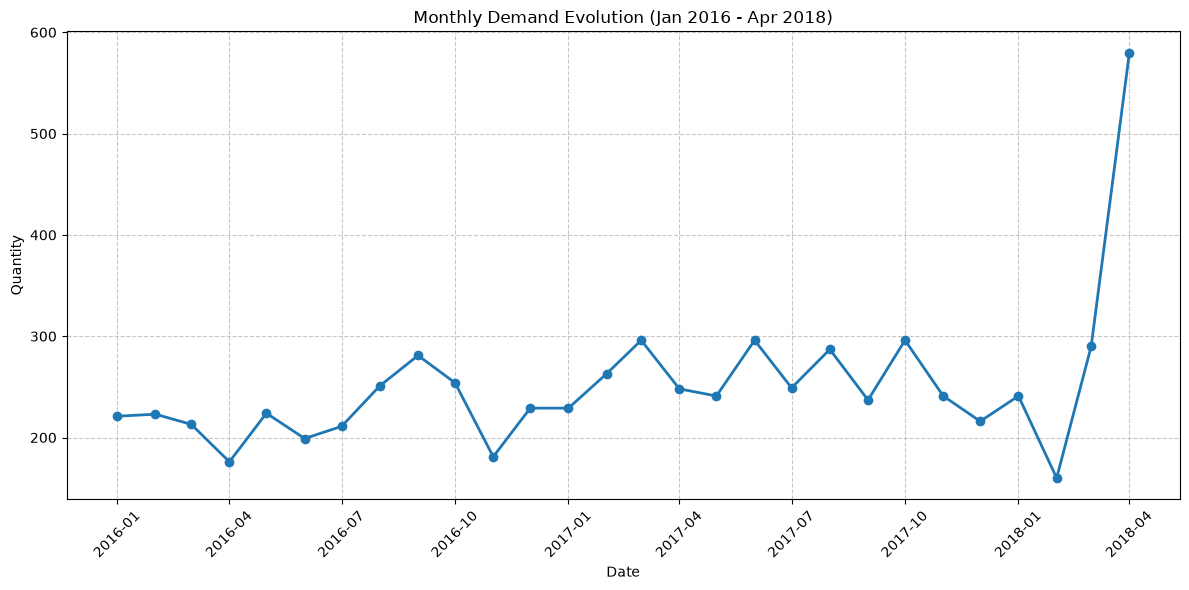

In [32]:
monthly_demand['periodo'] = pd.to_datetime(
    monthly_demand['order_year'].astype(str) + '-' + monthly_demand['order_month'].astype(str) + '-01'
)

start_date = '2016-01-01'
end_date = '2018-04-01'

df_filtered_time = monthly_demand[
    (monthly_demand['periodo'] >= start_date) & 
    (monthly_demand['periodo'] <= end_date)
]

plt.figure(figsize=(12, 6))
plt.plot(
    df_filtered_time['periodo'], 
    df_filtered_time['quantity'], 
    marker='o', 
    linestyle='-', 
    color='tab:blue', 
    linewidth=2
)

plt.title('Monthly Demand Evolution (Jan 2016 - Apr 2018)')
plt.xlabel('Date')
plt.ylabel('Quantity')
plt.grid(True, linestyle='--', alpha=0.7)
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [21]:
df_demand

,order_id,order_date,required_date,shipped_date,store_id,store_name,product_id,product_name,brand_id,brand_name,...,category_name,model_year,quantity,price,order_to_required_days,order_to_ship_days,shipped_vs_required_days,delivery_status,order_year,order_month
0,1,2016-01-01,2016-01-03,2016-01-03,1,Santa Cruz Bikes,20,Electra Townie Original 7D EQ - Women's - 2016,1,Electra,...,Cruisers Bicycles,2016,1,599.99,2,2.0,0.0,OnTime,2016,1
1,1,2016-01-01,2016-01-03,2016-01-03,1,Santa Cruz Bikes,8,Trek Remedy 29 Carbon Frameset - 2016,9,Trek,...,Mountain Bikes,2016,2,1799.99,2,2.0,0.0,OnTime,2016,1
2,1,2016-01-01,2016-01-03,2016-01-03,1,Santa Cruz Bikes,10,Surly Straggler - 2016,8,Surly,...,Cyclocross Bicycles,2016,2,1549.00,2,2.0,0.0,OnTime,2016,1
3,1,2016-01-01,2016-01-03,2016-01-03,1,Santa Cruz Bikes,16,Electra Townie Original 7D EQ - 2016,1,Electra,...,Cruisers Bicycles,2016,2,599.99,2,2.0,0.0,OnTime,2016,1
4,1,2016-01-01,2016-01-03,2016-01-03,1,Santa Cruz Bikes,4,Trek Fuel EX 8 29 - 2016,9,Trek,...,Mountain Bikes,2016,1,2899.99,2,2.0,0.0,OnTime,2016,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4717,1614,2018-11-28,2018-11-28,NaT,3,Rowlett Bikes,159,Trek Emonda ALR 6 - 2018,9,Trek,...,Road Bikes,2018,2,2299.99,0,NaN,NaN,Pending,2018,11
4718,1614,2018-11-28,2018-11-28,NaT,3,Rowlett Bikes,213,Electra Cruiser 1 - 2016/2017/2018,1,Electra,...,Cruisers Bicycles,2018,2,269.99,0,NaN,NaN,Pending,2018,11
4719,1615,2018-12-28,2018-12-28,NaT,3,Rowlett Bikes,197,Trek Verve+ Lowstep - 2018,9,Trek,...,Electric Bikes,2018,2,2299.99,0,NaN,NaN,Pending,2018,12
4720,1615,2018-12-28,2018-12-28,NaT,3,Rowlett Bikes,214,Electra Tiger Shark 3i - 2018,1,Electra,...,Cruisers Bicycles,2018,1,899.99,0,NaN,NaN,Pending,2018,12


# Stock

In [22]:
import pandas as pd

df_stock = pd.read_csv('stock.csv')

df_stock

,store_id,store_name,product_id,product_name,category_id,category_name,brand_id,brand_name,model_year,stock_quantity
0,1,Santa Cruz Bikes,1,Trek 820 - 2016,6,Mountain Bikes,9,Trek,2016,27
1,2,Baldwin Bikes,1,Trek 820 - 2016,6,Mountain Bikes,9,Trek,2016,14
2,3,Rowlett Bikes,1,Trek 820 - 2016,6,Mountain Bikes,9,Trek,2016,14
3,1,Santa Cruz Bikes,2,Ritchey Timberwolf Frameset - 2016,6,Mountain Bikes,5,Ritchey,2016,5
4,2,Baldwin Bikes,2,Ritchey Timberwolf Frameset - 2016,6,Mountain Bikes,5,Ritchey,2016,16
...,...,...,...,...,...,...,...,...,...,...
934,2,Baldwin Bikes,312,Electra Townie Commute 8D Ladies' - 2018,2,Comfort Bicycles,1,Electra,2018,2
935,3,Rowlett Bikes,312,Electra Townie Commute 8D Ladies' - 2018,2,Comfort Bicycles,1,Electra,2018,18
936,1,Santa Cruz Bikes,313,Electra Townie Original 1 Ladies' - 2018,2,Comfort Bicycles,1,Electra,2018,14
937,2,Baldwin Bikes,313,Electra Townie Original 1 Ladies' - 2018,2,Comfort Bicycles,1,Electra,2018,24


Statistics

In [23]:
df_stock.describe()

,store_id,product_id,category_id,brand_id,model_year,stock_quantity
count,939.000000,939.000000,939.000000,939.0000,939.000000,939.000000
mean,2.000000,157.000000,3.984026,5.4377,2017.562300,14.388711
std,0.816932,90.403007,2.168971,3.7020,0.642411,8.832070
min,1.000000,1.000000,1.000000,1.0000,2016.000000,0.000000
25%,1.000000,79.000000,2.000000,1.0000,2017.000000,7.000000
50%,2.000000,157.000000,3.000000,7.0000,2018.000000,14.000000
75%,3.000000,235.000000,6.000000,9.0000,2018.000000,22.000000
max,3.000000,313.000000,7.000000,9.0000,2018.000000,30.000000


In [24]:
total_stock = df_stock['stock_quantity'].sum()

total_stock

np.int64(13511)

In [25]:
stock_per_store = (
    df_stock.groupby(['store_id', 'store_name'])['stock_quantity']
    .sum()
    .reset_index()
)

stock_per_store

,store_id,store_name,stock_quantity
0,1,Santa Cruz Bikes,4532
1,2,Baldwin Bikes,4359
2,3,Rowlett Bikes,4620


In [26]:
stock_per_model_year = (
    df_stock.groupby('model_year')['stock_quantity']
    .sum()
    .reset_index()
)

stock_per_model_year

,model_year,stock_quantity
0,2016,1046
1,2017,3787
2,2018,8678


In [27]:
stock_per_product = (
    df_stock.groupby(['product_id', 'product_name', 'brand_name', 'category_name', 'model_year'])['stock_quantity']
    .sum()
    .reset_index()
    .sort_values(by='stock_quantity', ascending=False)
)

stock_per_product.head(5)

,product_id,product_name,brand_name,category_name,model_year,stock_quantity
187,188,Trek XM700+ Lowstep - 2018,Trek,Electric Bikes,2018,86
63,64,Electra Townie Original 7D - 2017,Electra,Cruisers Bicycles,2017,82
108,109,Sun Bicycles Cruz 7 - Women's - 2017,Sun Bicycles,Comfort Bicycles,2017,79
195,196,Trek Verve+ - 2018,Trek,Electric Bikes,2018,79
60,61,Trek Powerfly 8 FS Plus - 2017,Trek,Electric Bikes,2017,78


In [28]:
stock_per_brand = (
    df_stock.groupby('brand_name')['stock_quantity']
    .sum()
    .reset_index()
    .sort_values(by='stock_quantity', ascending=False)
)

stock_per_brand

,brand_name,stock_quantity
8,Trek,5519
0,Electra,4998
7,Surly,1105
6,Sun Bicycles,1042
1,Haro,454
5,Strider,136
2,Heller,108
3,Pure Cycles,104
4,Ritchey,45


In [29]:
stock_per_category = (
    df_stock.groupby('category_name')['stock_quantity']
    .sum()
    .reset_index()
    .sort_values(by='stock_quantity', ascending=False)
)

stock_per_category

,category_name,stock_quantity
2,Cruisers Bicycles,3378
5,Mountain Bikes,2654
0,Children Bicycles,2608
6,Road Bikes,2091
1,Comfort Bicycles,1258
4,Electric Bikes,1108
3,Cyclocross Bicycles,414
